# Linear Regression: House Prices

We use two known sales to build a straight-line prediction model.

| Size (sqft) | Actual price ($) |
|---|---:|
| 1000 | 300000 |
| 2000 | 500000 |

- `x_train` contains known sizes.
- `y_train` contains matching actual prices.
- We use full square feet and dollars throughout.

Our model is:

$$\text{predicted price} = \text{slope} \times \text{size} + \text{intercept}$$

## Import the Tools

- `numpy as np` provides arrays and numerical calculations.
- `matplotlib.pyplot as plt` provides plotting commands.

In [25]:
import numpy as np
import matplotlib.pyplot as plt

## Cost Function

This function evaluates a chosen slope and intercept.

- `total_cost = 0` starts a running total.
- `m = x_train.shape[0]` counts the training houses.
- `for i in range(m)` visits each house by its index.
- `slope * x_train[i] + intercept` calculates its predicted price.
- Subtracting `y_train[i]` gives predicted price minus actual price.
- `** 2` squares that error.
- `total_cost += cost_sum` adds this house's squared error.
- After the loop, divide the total by `2 * m`.
- Return the final cost.

Cost measures errors; it does not change the model.

In [84]:
def cost_func (x_train, y_train, slope, intercept):
    total_cost = 0; m = x_train.shape[0]

    for i in range(m):
        cost_sum = ( (slope * x_train[i]) + intercept - y_train[i] ) ** 2
        total_cost += cost_sum

    final_total_cost = total_cost / (2 * m) 

    return final_total_cost

## Prediction Function

This function applies the straight-line rule.

- `x_train` here is the function's input name. It receives the size I pass in.
- `slope` and `intercept` receive the model parameters.
- `return` gives back slope × size + intercept.

Despite the parameter name, this function can predict for a new size.

In [39]:
def y_pred (x_train, slope, intercept):
    return (slope * x_train) + intercept

## Calculate the Slope

This function finds the best-fitting slope using the training pairs.

- `x_bar` is the average size.
- `y_bar` is the average actual price.
- `numerator` and `denominator` start at zero.
- The loop visits every training index.
- For each house, multiply its size deviation by its matching price deviation.
- Add those products to `numerator`.
- Square each size deviation and add it to `denominator`.
- Divide the completed totals after the loop.
- Return the slope.

For our data, the slope is $200 per square foot.
The calculation requires variation in the sizes; otherwise the denominator is zero.

In [26]:
def slope (x_train, y_train):
    x_bar = np.mean(x_train)
    y_bar = np.mean(y_train)
    numerator = 0; denominator = 0

    for i in range(x_train.shape[0]):
        numerator += ((x_train[i] - x_bar) * (y_train[i] - y_bar))
        denominator += (x_train[i] - x_bar) ** 2

    slope = numerator / denominator

    return slope

## Calculate the Intercept

Intercept = average price − slope × average size.

For our data:
400,000 − 200 × 1,500 = 100,000 dollars.

The intercept positions the line vertically.
It does not establish the real price of a zero-size house.

In [29]:
def intercept (x_train, y_train, slope):
    return np.mean(y_train) - (slope * np.mean(x_train))

## Known Sales

Each size matches the actual price at the same index.

- Index 0: 1,000 sqft and $300,000.
- Index 1: 2,000 sqft and $500,000.

Keep these actual training pairs separate from new predictions.

In [57]:
x_train = np.array([1000, 2000])
y_train = np.array([300000, 500000])

## Arrays for the Graph

My prediction arrays start with the two known pairs.
Later, I add new sizes and their predicted prices.

Run this setup once.
Rerunning it resets the arrays to these two starting pairs.

In [56]:
x_predicted = np.array([1000, 2000])
y_predicted = np.array([300000, 500000])

## Inspect Array Shapes

`.shape` describes the array dimensions.
For our one-dimensional arrays, `(2,)` means two entries.

The f-string inserts each shape into the message.
`\n` starts a new line in the printed output.

In [31]:
print(f"The size of the x_train is {x_train.shape}\nThe size of the y_train is {y_train.shape}")

The size of the x_train is (2,)
The size of the y_train is (2,)


## Show the Calculated Parameters

The first statement calculates and prints the slope.

The second calculates the slope, passes it into the intercept function,
and prints the resulting intercept.

Expected results:
- Slope: 200.
- Intercept: 100,000.

In [32]:
print(f"The Slope for this regression is {slope(x_train, y_train)}")
print(f"The Intercept for this regression is {intercept(x_train, y_train, slope(x_train, y_train))}")

The Slope for this regression is 200.0
The Intercept for this regression is 100000.0


## Enter a New House Size

- `input` asks me to type a size.
- `int` converts the entered text to a whole number.
- `s` stores the calculated slope.
- `i` stores the calculated intercept.
- `pred` stores the prediction for this new size.
- The two append statements save the matching size-and-price pair.
- NumPy append returns a new array, so I assign it back.
- The final print displays both arrays.

Run this cell for each new prediction.
Each run adds one pair.

For 1,200 sqft, the predicted price is $340,000.

In [116]:
x_pred = int(input("Enter the sqft you want to predict:  "))
s = slope(x_train, y_train)
i = intercept(x_train, y_train, s)

pred = y_pred(x_pred, s, i)

x_predicted = np.append(x_predicted, x_pred)
y_predicted = np.append(y_predicted, pred)
print(x_predicted, y_predicted)

Enter the sqft you want to predict:   2500


[1000 2000 1200 1500 1700 2500] [300000. 500000. 340000. 400000. 440000. 600000.]


## Inspect the Saved Predictions

Print the current size and predicted-price arrays.
Values at the same position form one pair.

This only displays the arrays; it does not change them.

In [112]:
print(x_predicted, y_predicted)

[1000 2000] [300000. 500000.]


## Draw the Saved Pairs

- `scatter` draws a dot for each size-and-price pair.
- `plot` connects those pairs in their stored order.

Both arrays must have matching lengths and matching positions.
Rerun this cell after adding new predictions.

The generated predictions lie on the model's line by construction.
Their accuracy requires comparison with actual sale prices.

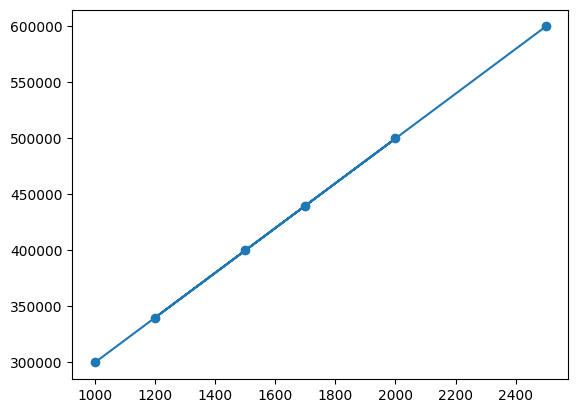

In [117]:
plt.scatter(x_predicted, y_predicted)
plt.plot(x_predicted, y_predicted)

## Compare Two Choices of Parameters

The first call evaluates:
- Slope: 1,000.
- Intercept: 100,000.
- Training cost: 800,000,000,000.

The second call evaluates the parameters calculated from our training data:
- Slope: 200.
- Intercept: 100,000.
- Training cost: 0.

Both calls use the same actual training pairs.
Only the parameter choice changes.

Cost has units of squared dollars.
Zero cost means this line matches these two sales exactly.
It does not guarantee accurate predictions for other houses.

In [88]:
print(f"The Cost on the training data: {cost_func(x_train, y_train, 1000, 100000)}")

The Cost on the training data: 800000000000.0


## Evaluate the Fitted Line

Calculate the slope from the training data.
Use that slope to calculate the intercept.
Pass both parameters and the actual training data into the cost function.

For our two known sales, the fitted line gives zero cost.
Triple quotes allow this f-string to span multiple lines.

In [91]:
print(f"""The Cost on the training data: {cost_func(x_train, y_train, 
                                                  slope(x_train, y_train), 
                                                  intercept(x_train, y_train, slope(x_train, y_train)))}""")

The Cost on the training data: 0.0
